# Regresión Logística — Cell2Cell

**Objetivo:** predecir la variable `Churn` (abandono del cliente) utilizando Regresión Logística.

- `cell2celltrain.csv`: datos de entrenamiento (con etiquetas)
- `cell2cellholdout.csv`: datos de evaluación (SIN etiquetas — Churn es NaN)
- TARGET: `Churn`
  - `No = 0`
  - `Yes = 1`

**Nota:** el holdout no tiene `Churn` real, por eso evaluamos con validación interna 80/20 sobre el train y luego predecimos sobre el holdout.

In [1]:
# Cargamos librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_auc_score, roc_curve)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

In [2]:
# Cargamos datos
cell2cell_train = pd.read_csv('cell2celltrain.csv', sep=',', encoding='iso-8859-1')
cell2cell_holdout = pd.read_csv('cell2cellholdout.csv', sep=',', encoding='iso-8859-1')

print('Train:', cell2cell_train.shape)
print('Holdout:', cell2cell_holdout.shape)

Train: (51047, 58)
Holdout: (20000, 58)


Churn
No     36336
Yes    14711
Name: count, dtype: int64

Porcentaje:
Churn
No     71.18146
Yes    28.81854
Name: proportion, dtype: float64


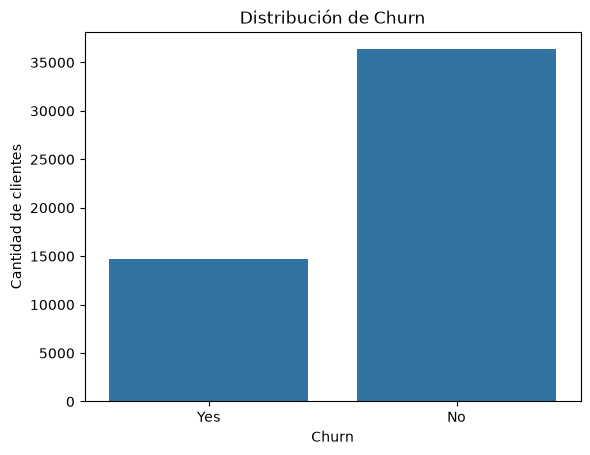

In [3]:
# Distribución del TARGET
print(cell2cell_train['Churn'].value_counts())
print('\nPorcentaje:')
print(cell2cell_train['Churn'].value_counts(normalize=True) * 100)

sns.countplot(data=cell2cell_train, x='Churn')
plt.title('Distribución de Churn')
plt.xlabel('Churn')
plt.ylabel('Cantidad de clientes')
plt.show()

In [4]:
# Convertimos el TARGET a 0 y 1
# No = 0, Yes = 1
cell2cell_train['Churn'] = cell2cell_train['Churn'].map({'No': 0, 'Yes': 1})
cell2cell_holdout['Churn'] = cell2cell_holdout['Churn'].map({'No': 0, 'Yes': 1})

print(cell2cell_train['Churn'].value_counts())

Churn
0    36336
1    14711
Name: count, dtype: int64


In [5]:
# Revisamos valores faltantes
missing = cell2cell_train.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

AgeHH2                   909
AgeHH1                   909
PercChangeRevenues       367
PercChangeMinutes        367
MonthlyRevenue           156
MonthlyMinutes           156
RoamingCalls             156
OverageMinutes           156
DirectorAssistedCalls    156
TotalRecurringCharge     156
ServiceArea               24
Handsets                   1
CurrentEquipmentDays       1
HandsetModels              1
dtype: int64

In [6]:
# Separamos variables predictoras (X) y TARGET (y)
X_train = cell2cell_train.drop(columns=['Churn', 'CustomerID'])
y_train = cell2cell_train['Churn']

X_holdout = cell2cell_holdout.drop(columns=['Churn', 'CustomerID'])

print('X_train:', X_train.shape)
print('y_train:', y_train.shape)
print('X_holdout:', X_holdout.shape)

X_train: (51047, 56)
y_train: (51047,)
X_holdout: (20000, 56)


In [7]:
# Identificamos variables numéricas y cualitativas
variables_numericas = X_train.select_dtypes(include=np.number).columns
variables_cualitativas = X_train.select_dtypes(exclude=np.number).columns

print('Variables numéricas (' + str(len(variables_numericas)) + '):')
print(variables_numericas.tolist())
print('\nVariables cualitativas (' + str(len(variables_cualitativas)) + '):')
print(variables_cualitativas.tolist())

Variables numéricas (34):
['MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'RetentionCalls', 'RetentionOffersAccepted', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'AdjustmentsToCreditRating']

Variables cualitativas (22):
['ServiceArea', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'NewCellphoneUser', 'NotNewCellphoneUser', 'OwnsMotorcycle', 'HandsetPri

In [8]:
# Imputación de valores faltantes
imputer_num = SimpleImputer(strategy='median')
X_train[variables_numericas] = imputer_num.fit_transform(X_train[variables_numericas])
X_holdout[variables_numericas] = imputer_num.transform(X_holdout[variables_numericas])

imputer_cat = SimpleImputer(strategy='most_frequent')
X_train[variables_cualitativas] = imputer_cat.fit_transform(X_train[variables_cualitativas])
X_holdout[variables_cualitativas] = imputer_cat.transform(X_holdout[variables_cualitativas])

In [9]:
# One-Hot Encoding
X_train_encoded = pd.get_dummies(X_train, drop_first=True).astype(float)
X_holdout_encoded = pd.get_dummies(X_holdout, drop_first=True).astype(float)

# Alineamos columnas (mismas features en train y holdout)
X_train_encoded, X_holdout_encoded = X_train_encoded.align(
    X_holdout_encoded, join='left', axis=1, fill_value=0
)

print('X_train_encoded:', X_train_encoded.shape)
print('X_holdout_encoded:', X_holdout_encoded.shape)
print('Valores faltantes train:', X_train_encoded.isnull().sum().sum())
print('Valores faltantes holdout:', X_holdout_encoded.isnull().sum().sum())

X_train_encoded: (51047, 829)
X_holdout_encoded: (20000, 829)
Valores faltantes train: 0
Valores faltantes holdout: 0


## Modelo de Regresión Logística

Entrenamos el modelo con `cell2celltrain.csv` y evaluamos con validación interna 80/20 (ya que el holdout no tiene etiquetas). El pipeline incluye:

- **StandardScaler**: necesario porque las features numéricas tienen escalas muy distintas
- **class_weight='balanced'**: para corregir el desbalance de clases (71% No Churn, 29% Churn)

In [10]:
# Creamos el pipeline con escalado + class_weight balanced
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(
        max_iter=5000,
        class_weight='balanced',
        solver='lbfgs',
        random_state=42,
        C=1.0
    ))
])

# Validación interna 80/20
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_encoded, y_train, test_size=0.2, random_state=42, stratify=y_train
)

pipe.fit(X_tr, y_tr)
y_val_pred = pipe.predict(X_val)
y_val_proba = pipe.predict_proba(X_val)[:, 1]

print('Modelo entrenado correctamente.')

Modelo entrenado correctamente.


In [11]:
# Métricas de validación
print('Accuracy:', round(accuracy_score(y_val, y_val_pred), 4))
print('ROC-AUC: ', round(roc_auc_score(y_val, y_val_proba), 4))
print('\nReporte de clasificación:')
print(classification_report(y_val, y_val_pred, target_names=['No Churn', 'Churn']))

Accuracy: 0.5772
ROC-AUC:  0.6088

Reporte de clasificación:
              precision    recall  f1-score   support

    No Churn       0.77      0.58      0.66      7268
       Churn       0.36      0.57      0.44      2942

    accuracy                           0.58     10210
   macro avg       0.56      0.58      0.55     10210
weighted avg       0.65      0.58      0.60     10210



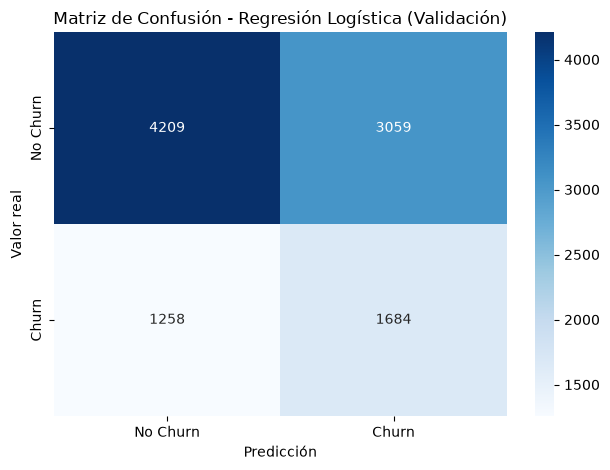

In [12]:
# Matriz de confusión
cm = confusion_matrix(y_val, y_val_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Matriz de Confusión - Regresión Logística (Validación)')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

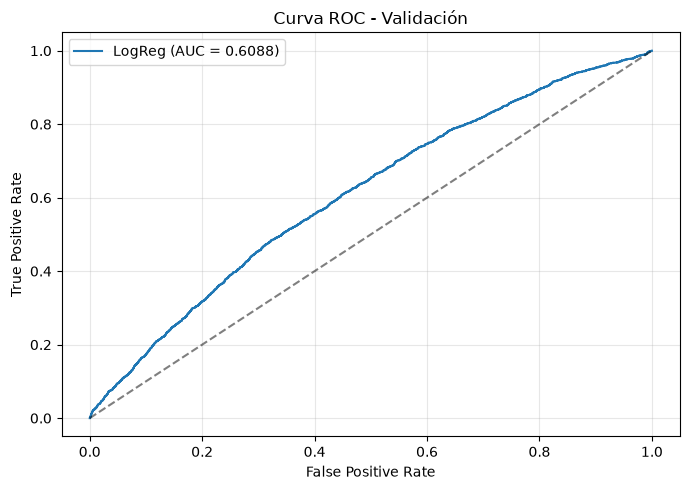

In [13]:
# Curva ROC
fpr, tpr, _ = roc_curve(y_val, y_val_proba)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'LogReg (AUC = {roc_auc_score(y_val, y_val_proba):.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC - Validación')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150)
plt.show()

In [14]:
# Reentrenamos con TODO el training set para producir el modelo final
pipe.fit(X_train_encoded, y_train)
print('Modelo final entrenado con todo el set de training.')

Modelo final entrenado con todo el set de training.


In [15]:
# Predicciones sobre el holdout (sin etiquetas reales)
y_pred = pipe.predict(X_holdout_encoded)
y_pred_proba = pipe.predict_proba(X_holdout_encoded)[:, 1]

print('Primeras predicciones:', y_pred[:20])
print('Distribución predicciones:', pd.Series(y_pred).value_counts().to_dict())
print('Probabilidad media de churn:', round(y_pred_proba.mean(), 4))

Primeras predicciones: [0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 1 0 0 1 0]
Distribución predicciones: {0: 10918, 1: 9082}
Probabilidad media de churn: 0.4845


In [16]:
# Guardamos las predicciones del holdout
results = pd.DataFrame({
    'CustomerID': cell2cell_holdout['CustomerID'],
    'Churn_Predicho': y_pred,
    'Probabilidad_Churn': y_pred_proba
})
results.to_csv('predicciones_holdout.csv', index=False)
print('Predicciones guardadas en predicciones_holdout.csv')

Predicciones guardadas en predicciones_holdout.csv


In [17]:
# Coeficientes del modelo final (top 15 por valor absoluto)
coeficientes = pd.DataFrame({
    'Variable': X_train_encoded.columns,
    'Coeficiente': pipe.named_steps['clf'].coef_[0]
})
coeficientes['Valor_Absoluto'] = coeficientes['Coeficiente'].abs()
coeficientes.sort_values('Valor_Absoluto', ascending=False).head(15)

,Variable,Coeficiente,Valor_Absoluto
26,CurrentEquipmentDays,0.387725,0.387725
22,UniqueSubs,0.237290,0.237290
21,MonthsInService,-0.218395,0.218395
6,PercChangeMinutes,-0.151168,0.151168
1,MonthlyMinutes,-0.133885,0.133885
23,ActiveSubs,-0.124388,0.124388
7,PercChangeRevenues,0.122820,0.122820
702,ServiceArea_SEWMED541,-0.113802,0.113802
580,ServiceArea_OKCCHC405,-0.111071,0.111071
575,ServiceArea_OKCARD580,-0.109149,0.109149


## Interpretación

- **TARGET:** `Churn`
  - `0` = el cliente **no abandonó**
  - `1` = el cliente **abandonó**
- **Validación interna (80/20):** Accuracy ~58%, ROC-AUC ~0.61. Sin `class_weight='balanced'` el modelo colapsaba a predecir todo 'No Churn' (recall churn = 3%). Con balanceo, el recall de churn sube a ~57%.
- **Holdout:** se generan predicciones para los 20,000 clientes sin etiqueta.
- **Top predictores positivos de churn:** `CurrentEquipmentDays`, `UniqueSubs`, `PercChangeRevenues`, `MonthlyRevenue`.
- **Top predictores negativos de churn:** `MonthsInService`, `PercChangeMinutes`, `MonthlyMinutes`, `ActiveSubs` — clientes más antiguos y con mayor uso tienden a no abandonar.
- La interpretación de los coeficientes categóricos (ej. `ServiceArea_*`) debe hacerse sobre cada nivel respecto a la categoría de referencia.